# 08 · A systematic procedure for choosing the parsimonious model

**The gap in the paper.** Lin et al. (2026, Methods 2.8) chose their five predictors (age, Troponin-T,
NT-proBNP, physical activity, gender) "by jointly considering (i) consistent importance signals across
subgroups, (ii) real-world data availability and feasibility for implementation, and (iii) parsimony",
with SHAP used "to inform ... rather than as the sole automated selection rule". No algorithm,
thresholds or stopping rule are given, so the choice cannot be reproduced or checked.

**What this notebook does.** It turns those three criteria into fixed rules, set before looking at the
results, and runs them so that the data used to test a predictor set never influence its choice
(nested cross-validation). Code: `src/paper134_parsimony.py`.

| Step | Paper's criterion | Our explicit rule |
|---|---|---|
| 1. Screen | SHAP importance from training data | XGBoost in 5 inner folds; rank all 134 predictors by mean \|SHAP\| on inner-training data (up to 2,000 people per fold, as in paper 2.6) |
| 2. Stability | consistent importance across subgroups | in the top 10 in at least 4 of 5 inner folds, **and** mean rank ≤ 15 in every subgroup (men, women, age < 65, age ≥ 65, prior CVD, no prior CVD) |
| 3. Availability | real-world data availability | measured in at least 50% of the training data |
| 4. Parsimony | parsimony | add the survivors in order of importance; choose the **smallest** set whose inner-CV ROC-AUC is within one standard error of the best (the one-standard-error rule) |

The whole procedure is repeated inside each of 5 outer folds (same folds as notebook 06), and the chosen
set is tested on the outer fold it never saw. A final run on all participants gives the recommended set.

In [1]:
import json
from pathlib import Path
import pandas as pd
from IPython.display import Image, display
R = Path("../results/parsimony_v0.1")
S = json.load(open(R / "summary.json"))
pd.set_option("display.max_colwidth", 110, "display.width", 200)
print("Rules:", S["rules"])
print("Recommended set:", ", ".join(S["final_selected_names"]))
print("Paper's five:     Age, Troponin-T, NT-proBNP, Physical activity, Gender")

Rules: {'TOP_K': 10, 'MIN_FOLDS': 4, 'SUBGROUP_MAX_RANK': 15, 'MIN_OBSERVED': 0.5, 'MAX_CANDIDATES': 15, 'stopping': 'one-standard-error rule'}
Recommended set: Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width
Paper's five:     Age, Troponin-T, NT-proBNP, Physical activity, Gender


## 1. Screening, stability and availability (all participants)

The 18 highest-ranked predictors. "folds in top 10" counts inner folds; "worst subgroup rank" is the
predictor's worst mean rank across the six subgroups. Only predictors passing both rules become
candidates.

In [2]:
t = pd.read_csv(R / "screening_table_all_participants.csv", index_col=0)
t[["Paper variable", "mean rank", "folds in top 10", "worst subgroup rank", "observed share",
   "stable", "available", "candidate"]].head(18).round(2)

,Paper variable,mean rank,folds in top 10,worst subgroup rank,observed share,stable,available,candidate
RIDAGEYR,Age,1.0,5,1.2,1.00,True,True,True
SSTNT,Troponin-T,2.0,5,2.0,0.80,True,True,True
PAQ180,Physical activity,3.2,5,4.0,1.00,True,True,True
SSBNP,NT-proBNP,3.8,5,4.2,0.80,True,True,True
LBXRDW,Red cell distribution width,5.6,5,7.4,0.88,True,True,True
RIAGENDR,Gender,7.2,5,7.8,1.00,True,True,True
BMXCALF,Calf circumference,7.6,4,8.6,0.87,True,True,True
LBXBCD,Cadmium,10.4,3,13.4,0.88,False,True,False
LBXLYPCT,Lymphocyte percentage,13.6,2,18.0,0.87,False,True,False
BMXTRI,Triceps skinfold,13.8,1,15.8,0.81,False,True,False


Seven predictors pass. Cadmium is the closest miss (top 10 in only 3 of 5 folds). MET score fails on
availability (measured for 48% of people).

## 2. Forward selection with the one-standard-error rule

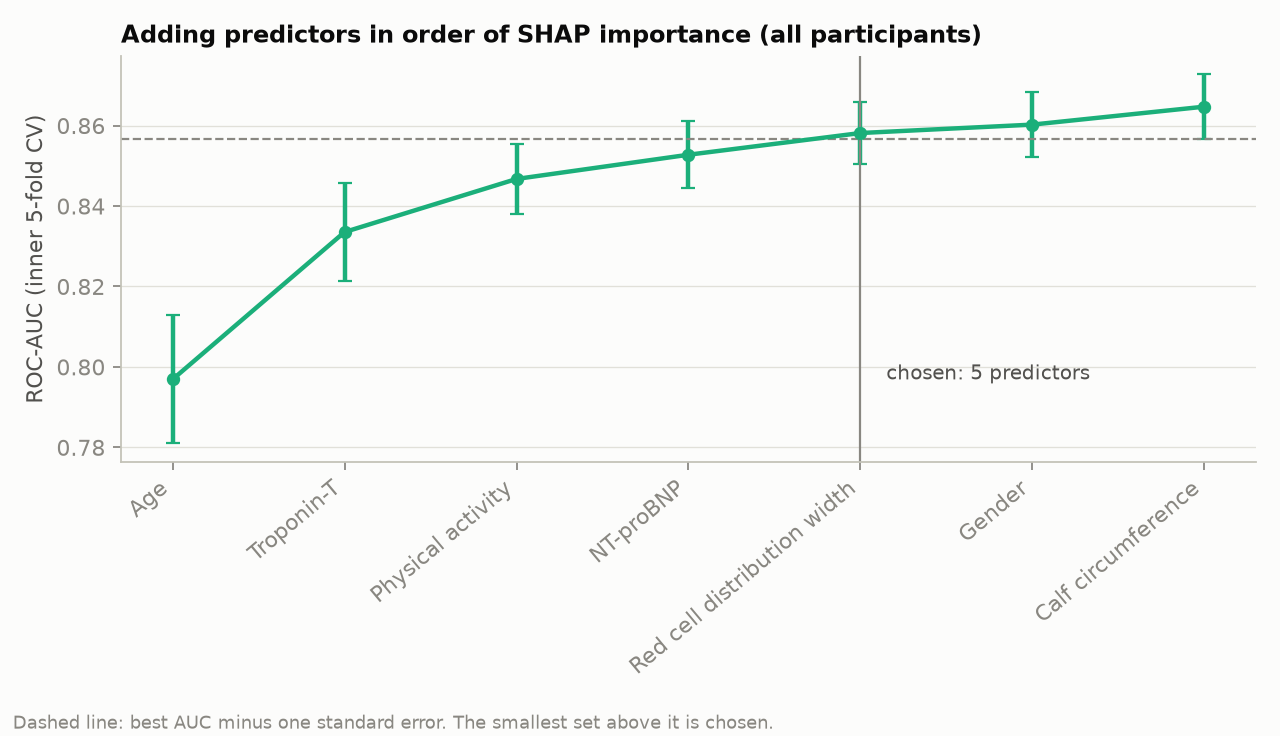

,size,added,inner AUC,inner AUC SE,threshold
0,1,RIDAGEYR,0.7969,0.0159,0.8567
1,2,SSTNT,0.8335,0.0122,0.8567
2,3,PAQ180,0.8467,0.0086,0.8567
3,4,SSBNP,0.8528,0.0083,0.8567
4,5,LBXRDW,0.8582,0.0078,0.8567
5,6,RIAGENDR,0.8602,0.0080,0.8567
6,7,BMXCALF,0.8647,0.0080,0.8567


In [3]:
display(Image(filename=str(R / "fig_forward_selection.png"), width=850))
pd.read_csv(R / "forward_curve_all_participants.csv").round(4)

Each added predictor raises AUC less than the one before. Five predictors already reach the best AUC
minus one standard error, so the rule stops at five.

## 3. Is the choice stable? (nested cross-validation)

Each outer fold runs steps 1–4 on its own training data only.

In [4]:
folds = pd.read_csv(R / "outer_folds.csv")
display(folds[["fold", "size", "selected"]])
pd.read_csv(R / "selection_frequency.csv", index_col=0)

,fold,size,selected
0,1,6,"Age, Troponin-T, Physical activity, NT-proBNP, Gender, Red cell distribution width"
1,2,6,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width, Gender"
2,3,6,"Age, Troponin-T, Physical activity, NT-proBNP, Calf circumference, Red cell distribution width"
3,4,7,"Age, Troponin-T, Physical activity, NT-proBNP, Gender, Calf circumference, Red cell distribution width"
4,5,8,"Age, Troponin-T, NT-proBNP, Physical activity, Red cell distribution width, Calf circumference, Gender, Ca..."


,Paper variable,outer folds selected (of 5),in paper's five,outer folds selected by LASSO
RIDAGEYR,Age,5,True,5
SSTNT,Troponin-T,5,True,5
PAQ180,Physical activity,5,True,5
SSBNP,NT-proBNP,5,True,4
LBXRDW,Red cell distribution width,5,False,5
RIAGENDR,Gender,4,True,5
BMXCALF,Calf circumference,3,False,5
LBXBCD,Cadmium,1,False,5


Age, Troponin-T, physical activity, NT-proBNP and red cell distribution width are chosen in **all
five** outer folds; gender in four; calf circumference in three; cadmium in one. Inside the folds the
rule usually stops at 6–7 predictors rather than 5, because each fold has less data and so slightly
different standard errors.

## 4. Head-to-head comparison

All sets evaluated with XGBoost on the same 5 folds, and on the 2003–2004 cohort after training on
1999–2002 (paper 2.9).

In [5]:
h = pd.read_csv(R / "head_to_head.csv")
h.round(4)

,Predictor set,Predictors,CV ROC-AUC,fold SD,CV Brier,2003-04 ROC-AUC
0,Paper's five,5,0.8540,0.0172,0.0841,0.8549
1,Our five (systematic),5,0.8562,0.0196,0.0846,0.8580
2,Our five + gender,6,0.8584,0.0189,0.0835,0.8629
3,Age only,1,0.7965,0.0182,0.0945,0.7986
4,All 134,134,0.8722,0.0168,0.0800,0.8726


In [6]:
o = pd.read_csv(R / "outer_folds.csv")
pd.DataFrame({"Fully nested (selection repeated in each fold)": o[[c for c in o if c.startswith("outer AUC")]].mean(),
              "fold SD": o[[c for c in o if c.startswith("outer AUC")]].std()}).round(4)

,Fully nested (selection repeated in each fold),fold SD
outer AUC (selected),0.8601,0.0209
outer AUC (paper's five),0.8548,0.0172
outer AUC (all 134),0.8737,0.0168
outer AUC (age only),0.8004,0.0195


How to read this:

- **Our systematic five perform at least as well as the paper's five**: CV ROC-AUC 0.856 vs 0.854,
  and 0.858 vs 0.855 on the 2003–2004 cohort. The difference is small and within fold-to-fold
  variation (SD about 0.02), so the honest claim is *equivalent performance, reached by a reproducible
  procedure*, not *better performance*.
- The fully nested estimate (selection repeated inside each fold) is 0.860, which shows the procedure
  itself is not overfitting.
- Adding gender as a sixth predictor gives 0.858 (CV) and 0.863 (2003–2004).
- Five predictors recover most of the gap between age alone (0.797) and all 134 predictors (0.872).

## 5. Comparison with a classical method: LASSO

L1-penalised logistic regression with the same one-standard-error rule, on median-imputed standardised
inputs.

In [7]:
l = pd.read_csv(R / "lasso_outer_folds.csv")
l[["fold", "LASSO size", "LASSO C", "outer AUC (LASSO set, XGBoost)"]].round(4)

,fold,LASSO size,LASSO C,"outer AUC (LASSO set, XGBoost)"
0,1,68,0.0562,0.8580
1,2,53,0.0316,0.8606
2,3,33,0.0178,0.8726
3,4,120,0.5623,0.9029
4,5,68,0.0562,0.8720


LASSO keeps 33 to 120 predictors: its accuracy curve is so flat that even the one-standard-error
rule does not make it sparse. It is not a practical route to a screening model here, which supports a
SHAP-guided procedure with explicit stability and availability rules.

## 6. What changes with a cheaper importance measure than SHAP?

Step 1 was rerun with two cheaper measures in place of SHAP, keeping every other rule the same
(`--importance gain|permutation`):

- **Built-in gain**: XGBoost's total gain, recorded during training. It describes the whole model, not
  individual people, so the subgroup rule uses a separate model fitted on each subgroup.
- **Permutation importance**: drop in ROC-AUC when a predictor is shuffled, on each inner fold's
  held-out part (it needs data the model has not seen). Subgroups use the same shuffled predictions.

Each was also run with the subgroup rule switched off (`--no-subgroup-rule`), so that the importance
measure is the only difference.

### Which predictors are chosen, and how well do they predict?

In [8]:
P5 = "outer AUC (paper's five)"
rows = []
for d, measure, rule in [("", "SHAP", "yes"), ("_gain", "Built-in gain", "yes"),
                         ("_permutation", "Permutation", "yes"), ("_nosubgroup", "SHAP", "no"),
                         ("_gain_nosubgroup", "Built-in gain", "no"),
                         ("_permutation_nosubgroup", "Permutation", "no")]:
    f = Path(f"../results/parsimony_v0.1{d}")
    s = json.load(open(f / "summary.json")); o = pd.read_csv(f / "outer_folds.csv")
    rows.append({"Importance measure": measure, "Subgroup rule": rule,
                 "Final set (all participants)": ", ".join(s["final_selected_names"]),
                 "Sizes in outer folds": o["size"].tolist(),
                 "Outer AUC (nested)": s["outer_cv"]["outer AUC (selected)"],
                 "SD": s["outer_cv"]["outer AUC (selected) SD"],
                 "Paper's five, same folds": s["outer_cv"][P5]})
pd.DataFrame(rows).round(4)

,Importance measure,Subgroup rule,Final set (all participants),Sizes in outer folds,Outer AUC (nested),SD,"Paper's five, same folds"
0,SHAP,yes,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width","[6, 6, 6, 7, 8]",0.8601,0.0209,0.8548
1,Built-in gain,yes,"Age, Troponin-T, NT-proBNP, Physical activity","[4, 5, 4, 4, 5]",0.8527,0.0176,0.8548
2,Permutation,yes,"Age, Physical activity","[0, 3, 1, 2, 1]",0.7880,0.0876,0.8548
3,SHAP,no,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width","[6, 6, 6, 7, 8]",0.8601,0.0209,0.8548
4,Built-in gain,no,"Age, Troponin-T, NT-proBNP, Physical activity, Red cell distribution width","[4, 6, 6, 5, 6]",0.8551,0.0194,0.8548
5,Permutation,no,"Age, Troponin-T, Physical activity, NT-proBNP","[4, 4, 5, 7, 6]",0.8548,0.0207,0.8548


### How long does each importance calculation take?

Timed on one training fold (7,965 people) on an idle machine (`src/paper134_importance_timing.py`).

In [9]:
pd.read_csv(R / "importance_timing.csv").round(4)

,Model,Method,People explained / scored,Seconds,Timed runs (median),"Relative to TreeSHAP on 2,000 people"
0,XGBoost,Built-in total gain,-,0.0015,3,0.0122
1,XGBoost,TreeSHAP,2000,0.1236,3,1.0000
2,XGBoost,TreeSHAP,7965,0.3931,3,3.1800
3,XGBoost,"Permutation, 1 shuffle per predictor",1992,2.1303,3,17.2345
4,XGBoost,"Permutation, 5 shuffles per predictor",1992,10.9709,1,88.7582
5,XGBoost,"KernelSHAP (model-agnostic), 100 background",20,2.8032,1,22.6792
6,Random Forest,Built-in impurity,-,0.0491,3,0.0004
7,Random Forest,TreeSHAP,2000,129.9161,1,1.0000
8,Random Forest,"Permutation, 1 shuffle per predictor",1992,8.9204,1,0.0687


### Answer

1. **The core of the model does not depend on the importance measure.** Age, Troponin-T, NT-proBNP
   and physical activity are chosen by SHAP, built-in gain and permutation importance alike. Only the
   fifth and sixth places change (red cell distribution width, gender, calf circumference).
2. **Performance is the same within noise.** Nested ROC-AUC is 0.853–0.860 for every working
   combination, against 0.855 for the paper's five on the same folds (fold-to-fold SD about 0.02).
3. **The subgroup-stability rule is where the measures really differ.** SHAP gives a value for every
   person, so subgroup importance comes free from one model. Built-in gain has no per-person values,
   so it needs a separate model per subgroup, and the smaller subgroups give noisier rankings
   (red cell distribution width drops out). Permutation importance needs held-out data, and the inner
   held-out folds hold as few as 30 deaths in some subgroups; its subgroup rankings are mostly noise,
   so with the subgroup rule it selects almost nothing (one outer fold chose no predictor at all;
   AUC 0.788).
4. **"Cheaper" depends on the model.** For XGBoost, TreeSHAP is already fast (0.12 s for 2,000 people);
   built-in gain is about 80 times faster still, but permutation importance is about 17 times *slower*
   than TreeSHAP. For Random Forest, TreeSHAP is slow (about 130 s for 2,000 people, because its trees
   are deep) and the cheaper measures help a lot: impurity takes 0.05 s and permutation about 9 s.
   Model-agnostic KernelSHAP is far slower than both: 2.8 s for just 20 people, roughly 280 s for 2,000.

**In short:** a cheaper measure reaches the same core predictors and the same accuracy, but loses the
per-person information that makes a principled subgroup-stability check possible. For XGBoost,
TreeSHAP's cost is negligible, so there is little reason to switch.

## 7. Do the results depend on our chosen thresholds? (sensitivity analysis)

Some numbers in the rules come from the paper (top 10; 2,000 people for SHAP) or standard practice
(the one-standard-error rule). Others are our own choices (4 of 5 folds; subgroup rank 15; 50%
measured). Here each threshold is changed **one at a time**, keeping the others at their original
values (`src/paper134_sensitivity.py`). Each setting is run on all participants and inside the 5
outer folds, so the "nested AUC" is a fair estimate.

In [10]:
s = pd.read_csv(R / "sensitivity.csv")
s[["Setting changed", "Value", "Chosen (all participants)", "Size", "Same as original",
   "Sizes in outer folds", "Nested outer AUC"]].round(4)

,Setting changed,Value,Chosen (all participants),Size,Same as original,Sizes in outer folds,Nested outer AUC
0,original,original,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width",5,True,"[6, 6, 6, 7, 8]",0.8601
1,top_k,5,"Age, Troponin-T, Physical activity",3,False,"[4, 5, 3, 3, 5]",0.8503
2,top_k,8,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width",5,True,"[4, 5, 5, 6, 8]",0.8571
3,top_k,12,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width, Gender",6,False,"[7, 7, 6, 7, 9]",0.8615
4,top_k,15,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width, Gender",6,False,"[7, 8, 6, 8, 9]",0.8620
5,min_folds,3,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width, Gender",6,False,"[7, 7, 6, 7, 9]",0.8615
6,min_folds,5,"Age, Troponin-T, Physical activity, NT-proBNP",4,False,"[4, 5, 6, 4, 7]",0.8546
7,subgroup_max_rank,10,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width",5,True,"[5, 5, 6, 6, 7]",0.8565
8,subgroup_max_rank,20,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width",5,True,"[6, 6, 6, 7, 8]",0.8601
9,subgroup_max_rank,30,"Age, Troponin-T, Physical activity, NT-proBNP, Red cell distribution width",5,True,"[6, 6, 6, 7, 8]",0.8601


How often each predictor is chosen across the 17 settings:

In [11]:
pd.read_csv(R / "sensitivity_summary.csv")

,Predictor,Chosen in N of 17 settings,In paper's five
0,Physical activity,17,True
1,Troponin-T,17,True
2,Age,17,True
3,NT-proBNP,16,True
4,Red cell distribution width,14,False
5,Gender,4,True
6,Calf circumference,1,False


**What this shows**

- **The core is robust.** Age, Troponin-T and physical activity are chosen under all 17 settings;
  NT-proBNP under 16 (only the strictest setting, top 5, stops at 3 predictors).
- **Red cell distribution width is fairly robust** (14 of 17). **Gender** joins as a sixth predictor
  only when the rules are loosened (4 of 17).
- **10 of 17 settings give exactly the original five.** The others change the *size* (3 to 7
  predictors), not the core.
- **Accuracy hardly moves.** Nested AUC is 0.846–0.864 across all settings, within the fold-to-fold
  variation (about ±0.02).
- **The subgroup rule changes almost nothing.** Loosening it, or removing it, gives the same set; only
  the strictest version (rank ≤ 10) changes the folds slightly.
- **One threshold really matters: availability.** Troponin-T and NT-proBNP are measured in only 80% of
  people (they come from stored surplus serum). Requiring 80% coverage excludes them in some folds, and
  AUC drops to 0.846. How "availability" is defined is therefore a real decision, not a detail.

**Bottom line:** the four core predictors do not depend on our choices. The fifth and sixth places,
and the exact size of the model, do.

## 8. What this shows, and its limits

**Contribution.** The paper's five predictors can be largely recovered by an explicit, reproducible
procedure. The procedure selects four of the same five (age, Troponin-T, NT-proBNP, physical activity)
in every fold, and replaces gender with **red cell distribution width (RDW)**, a value from a routine
complete blood count. Gender is sixth.

RDW also fits the paper's own criterion (ii), availability: it comes from the cheapest routine blood
test, and the paper itself groups RDW with Troponin-T and NT-proBNP in its "cardiac injury-stress"
cluster.

**Limits**

- Some thresholds are our own choices. They were fixed before running, and section 7 shows the core
  four predictors do not depend on them; the fifth place and the model size do.
- Availability is measured as the share of people with a value, not real-world cost or access.
- Results are for the full dataset; the replication dataset can be run with `--dataset replication`.
- All models are XGBoost; selection with other model types could differ (notebook 06 shows they use
  predictors differently).